# Imports

In [74]:
import shutil
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset

In [75]:
train = pd.read_csv('./data/train.csv')
test  = pd.read_csv('./data/test.csv')

## Train Overview

In [76]:
train.shape

(891, 12)

In [77]:
# Train data overview
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [78]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [79]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


In [80]:
# missing values overview
missing = pd.DataFrame({
    "missing_count": train.isna().sum(),
    "missing_pct": train.isna().mean() * 100
}).sort_values("missing_pct", ascending=False)

display(missing)

,missing_count,missing_pct
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000


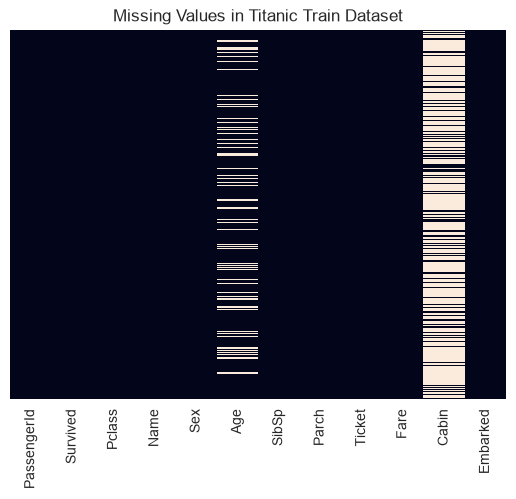

In [81]:
sns.heatmap(train.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Titanic Train Dataset")
plt.show()

In [82]:
train['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [83]:
train['Survived'].value_counts(normalize=True)

Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64

In [84]:
# Since Survived is binary (0 or 1), its mean within a group equals the proportion of passengers who survived.
train.groupby('Pclass')['Survived'].mean()

Pclass
1    0.629630
2    0.472826
3    0.242363
Name: Survived, dtype: float64

In [85]:
train.groupby('Sex')['Survived'].mean()

Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64

In [86]:
train.groupby('Embarked')['Survived'].mean()

Embarked
C    0.553571
Q    0.389610
S    0.336957
Name: Survived, dtype: float64

### Visualize the survival rates
The following bar plots show the survival rates based on passenger class, sex, and embarkation port. The y-axis represents the survival rate (proportion of passengers who survived), while the x-axis represents the different categories within each feature.

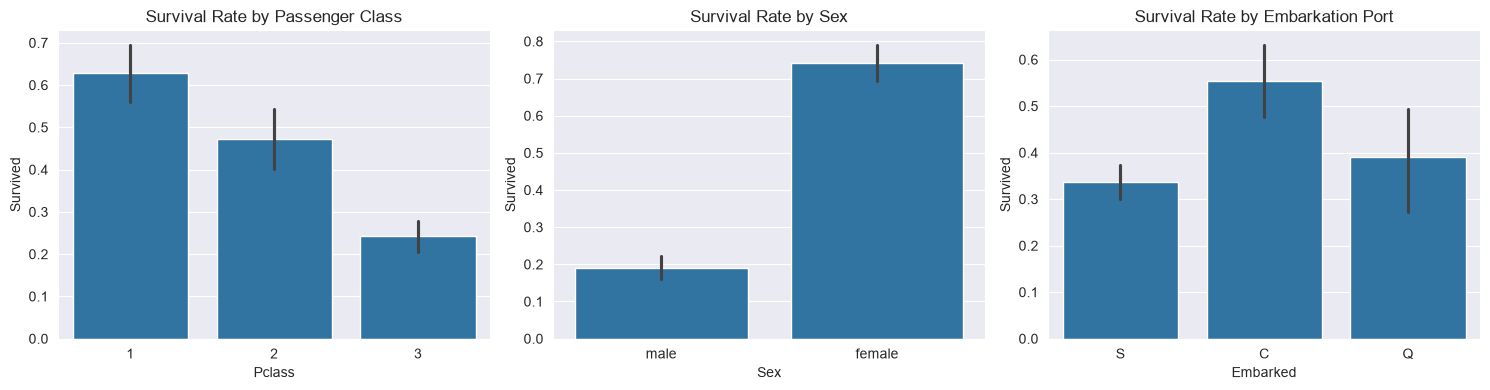

In [87]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=train, x='Pclass', y='Survived', ax=axes[0])
axes[0].set_title('Survival Rate by Passenger Class')

sns.barplot(data=train, x='Sex', y='Survived', ax=axes[1])
axes[1].set_title('Survival Rate by Sex')

sns.barplot(data=train, x='Embarked', y='Survived', ax=axes[2])
axes[2].set_title('Survival Rate by Embarkation Port')

plt.tight_layout()
plt.show()

Its looks like that the survival rate is higher for females, passengers in higher classes, and those who embarked from certain ports.

### Analyze Age and Fare
The following histograms show the distribution of Age and Fare for passengers who survived and those who did not. The distributions can provide insights into how these continuous variables relate to survival.


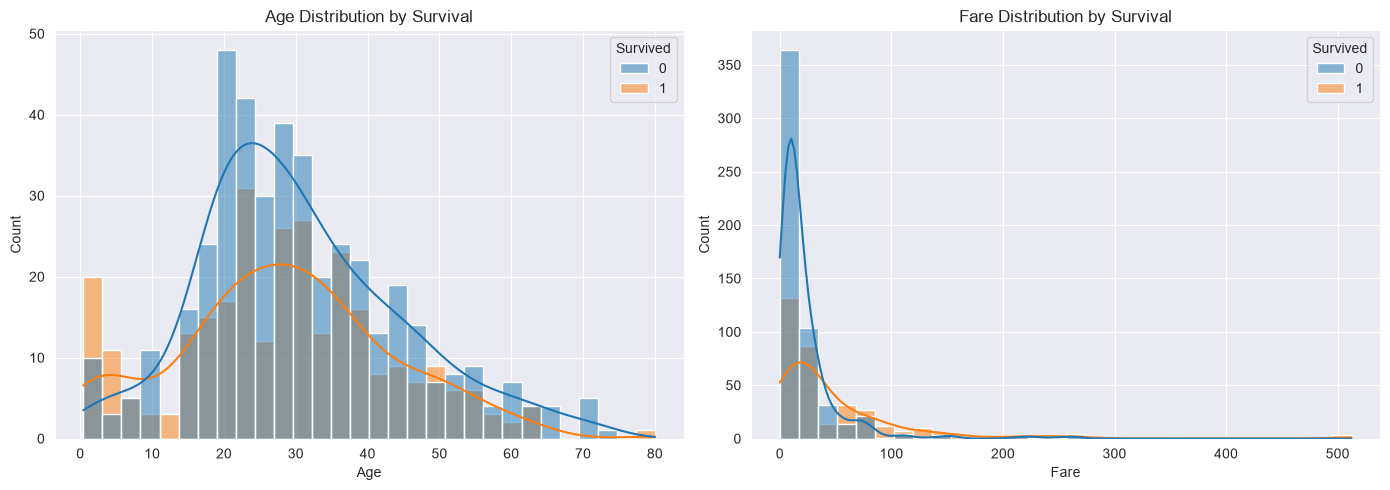

In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution by survival
sns.histplot(
    data=train,
    x='Age',
    hue='Survived',
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].set_title('Age Distribution by Survival')
axes[0].set_xlabel('Age')

# Fare distribution by survival
sns.histplot(
    data=train,
    x='Fare',
    hue='Survived',
    bins=30,
    kde=True,
    ax=axes[1]
)
axes[1].set_title('Fare Distribution by Survival')
axes[1].set_xlabel('Fare')

plt.tight_layout()
plt.show()

Its looks like that younger passengers and those who paid higher fares had a higher survival rate.

### Compare distributions using boxplots
Histograms show the overall distributions, while boxplots help us compare medians, spread, and potential outliers.

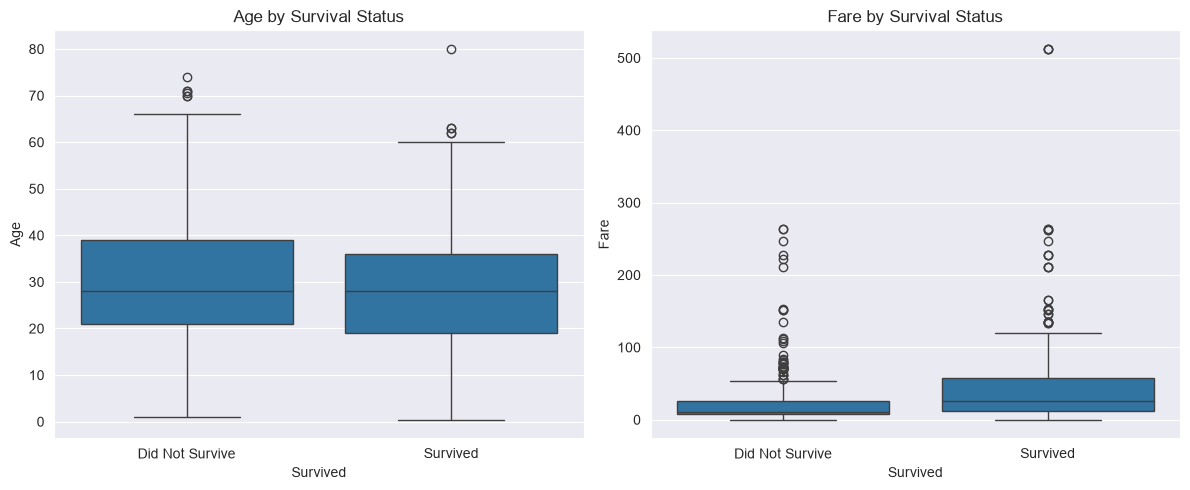

In [89]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=train, x='Survived', y='Age', ax=axes[0])
axes[0].set_title('Age by Survival Status')
axes[0].set_xticks([0, 1], ['Did Not Survive', 'Survived'])

sns.boxplot(data=train, x='Survived', y='Fare', ax=axes[1])
axes[1].set_title('Fare by Survival Status')
axes[1].set_xticks([0, 1], ['Did Not Survive', 'Survived'])

plt.tight_layout()
plt.show()

It looks like that passengers who survived were generally younger and paid higher fares.

In [90]:
print("Age statistics by survival status:")
print(train.groupby('Survived')['Age'].describe().round(2))

print("\nFare statistics by survival status:")
print(train.groupby('Survived')['Fare'].describe().round(2))

Age statistics by survival status:
          count   mean    std   min   25%   50%   75%   max
Survived                                                   
0         424.0  30.63  14.17  1.00  21.0  28.0  39.0  74.0
1         290.0  28.34  14.95  0.42  19.0  28.0  36.0  80.0

Fare statistics by survival status:
          count   mean    std  min    25%   50%   75%     max
Survived                                                     
0         549.0  22.12  31.39  0.0   7.85  10.5  26.0  263.00
1         342.0  48.40  66.60  0.0  12.48  26.0  57.0  512.33


The exploratory analysis indicates that passengers who survived were younger on average (28.34 years) than passengers who did not survive (30.63 years). However, both groups had a median age of 28 years, suggesting that the difference between their age distributions is relatively modest.

Survivors also paid higher fares on average (48.40 compared with 22.12) and had a higher median fare (26.00 compared with 10.50). Fare may therefore provide useful predictive information, although its large standard deviation and maximum values suggest a skewed distribution and potential outliers.

The missing-value analysis identified substantial missingness in Cabin (77.10%) and Age (19.87%), while Embarked had only two missing values. These findings motivate median imputation for numerical features, most-frequent imputation for Embarked, and further investigation of cabin-derived features.

These observations describe associations in the dataset and do not establish causal relationships.

### Analysis family-related

Survival rate by family size:
            count  SurvivalRate
FamilySize                     
1             537         0.304
2             161         0.553
3             102         0.578
4              29         0.724
5              15         0.200
6              22         0.136
7              12         0.333
8               6         0.000
11              7         0.000


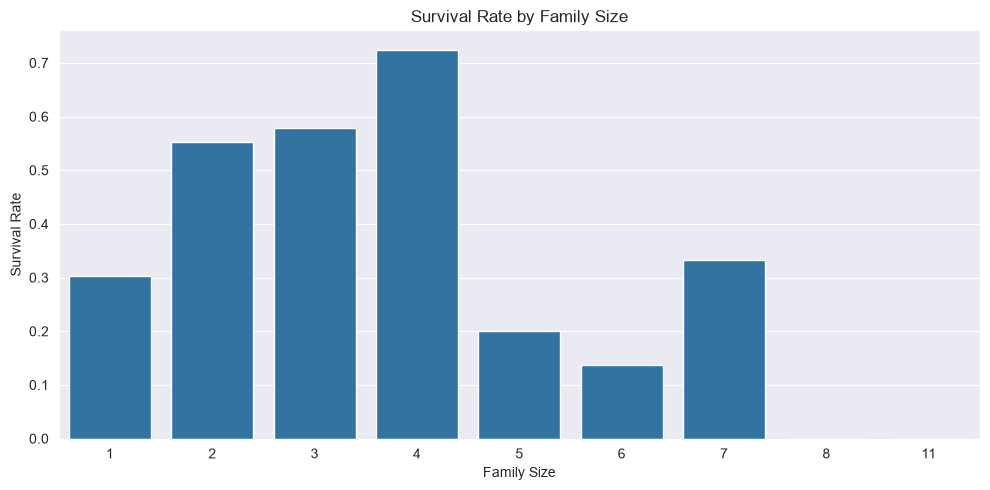

In [91]:
train_eda = train.copy()
train_eda['FamilySize'] = (
    train_eda['SibSp'] + train_eda['Parch'] + 1
)

# Survival rate by family size
print("Survival rate by family size:")
print(
    train_eda.groupby('FamilySize')['Survived']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'SurvivalRate'})
    .round(3)
)

# Visualize survival rate by family size
plt.figure(figsize=(10, 5))
sns.barplot(
    data=train_eda,
    x='FamilySize',
    y='Survived',
    errorbar=None
)
plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

Family size was calculated as the number of siblings/spouses (SibSp) plus the number of parents/children (Parch) plus one for the passenger. The analysis shows that passengers traveling alone had a survival rate of 30.4%, whereas passengers in families of two to four had survival rates ranging from 55.3% to 72.4%.

For family sizes of five or more, survival rates were generally lower, although these groups contained relatively few passengers. Consequently, their observed rates should be interpreted cautiously.

These findings suggest that family size may be a useful predictive feature. Both FamilySize and an IsAlone indicator will be considered during preprocessing and model evaluation.

### Passenger's title
Titles such as Mr., Mrs., Miss, and Master may capture differences that are not fully represented by the existing features.

In [92]:
# Extract passenger titles from names
train_eda['Title'] = train_eda['Name'].str.extract(
    r',\s*([^.]*)\.',
    expand=False
).str.strip()

# Examine title frequencies and survival rates
print("Survival rate by title:")
print(
    train_eda.groupby('Title')['Survived']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'SurvivalRate'})
    .sort_values('count', ascending=False)
    .round(3)
)

Survival rate by title:
              count  SurvivalRate
Title                            
Mr              517         0.157
Miss            182         0.698
Mrs             125         0.792
Master           40         0.575
Dr                7         0.429
Rev               6         0.000
Major             2         0.500
Col               2         0.500
Mlle              2         1.000
Sir               1         1.000
Ms                1         1.000
Capt              1         0.000
Mme               1         1.000
Lady              1         1.000
Jonkheer          1         0.000
Don               1         0.000
the Countess      1         1.000


Passengers with the title Mr had a substantially lower survival rate than passengers with the titles Miss and Mrs. This is consistent with the survival differences by sex that we would expect to observe in the Titanic dataset.
The title may capture information about both sex and social status, but it is not necessarily an independent predictor. We should examine its relationship with Sex and Pclass before deciding how to use it in a model.

### Consolidate rare
Why this matters: If title differences largely reflect sex differences, Title may add limited new information. If survival patterns also differ across passenger classes, title may capture additional useful information.

In [93]:
common_titles = ["Mr", "Miss", "Mrs", "Master"]

train_eda["Title_Grouped"] = train_eda["Title"].apply(
    lambda title: title if title in common_titles else "Rare"
)

title_survival = (
    train_eda.groupby("Title_Grouped")["Survived"]
      .agg(count="count", SurvivalRate="mean")
      .sort_values("SurvivalRate", ascending=False)
)

title_survival["SurvivalRate"] = (
    title_survival["SurvivalRate"].round(3)
)

print(title_survival)

               count  SurvivalRate
Title_Grouped                     
Mrs              125         0.792
Miss             182         0.698
Master            40         0.575
Rare              27         0.444
Mr               517         0.157


In [94]:
print(pd.crosstab(train_eda["Title_Grouped"], train_eda["Sex"]))

Sex            female  male
Title_Grouped              
Master              0    40
Miss              182     0
Mr                  0   517
Mrs               125     0
Rare                7    20


In [95]:
print(
    train_eda.pivot_table(
        values="Survived",
        index="Title_Grouped",
        columns="Pclass",
        aggfunc="mean"
    ).round(3)
)

Pclass             1      2      3
Title_Grouped                     
Master         1.000  1.000  0.393
Miss           0.957  0.941  0.500
Mr             0.346  0.088  0.113
Mrs            0.976  0.902  0.500
Rare           0.611  0.111    NaN


Results show:
- Mr: 15.7% survived.
- Master: 57.5% survived.
That's a substantial difference between two groups that are both male.
So Title may provide useful information that Sex alone doesn't capture.
The difference might partly be explained by age. If we already include Age in our model, Title might contribute little additional information.

### Check missing values in Age

In [96]:
print("Missing Age:", train_eda["Age"].isna().sum())
print("Total passengers:", len(train_eda))
print("Missing Age (%):", round(train_eda["Age"].isna().mean() * 100, 2))

Missing Age: 177
Total passengers: 891
Missing Age (%): 19.87


### Age varies strongly by title
Before deciding how to fill the ~20% missing ages, we check whether Age is reasonably homogeneous across groups. Imputing by `(Pclass, Sex)` would treat a 3rd-class boy ("Master") as a 25-year-old man — a sizable error for the group with the strongest survival signal. Grouping by `Title` captures that `Master` passengers are children while `Mr`/`Mrs`/`Rare` are adults, so `(Pclass, Title)` medians give much more accurate fills.

               count  mean   50%   std
Title_Grouped                         
Master          36.0   4.6   3.5   3.6
Miss           146.0  21.8  21.0  13.0
Mr             398.0  32.4  30.0  12.7
Mrs            108.0  35.9  35.0  11.4
Rare            26.0  42.4  44.5  13.2


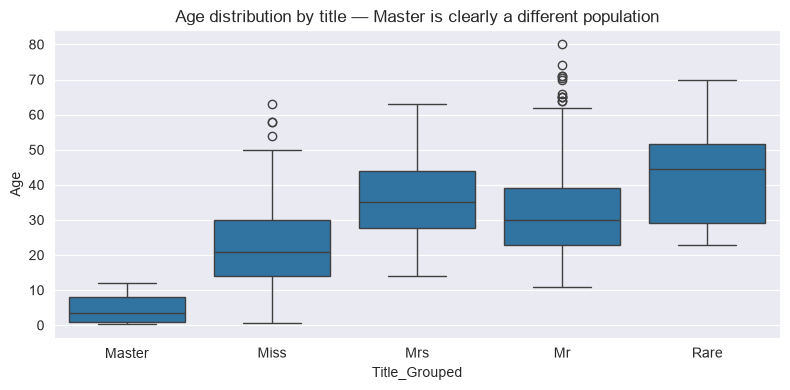

In [97]:
age_by_title = train_eda.groupby("Title_Grouped")["Age"].describe()[
    ["count", "mean", "50%", "std"]
].round(1)
print(age_by_title)

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=train_eda,
    x="Title_Grouped",
    y="Age",
    order=["Master", "Miss", "Mrs", "Mr", "Rare"],
)
plt.title("Age distribution by title — Master is clearly a different population")
plt.tight_layout()
plt.show()

### Correlation of numeric features
The heatmap below shows pairwise Pearson correlations between the numeric features. It highlights which variables move together and which are most associated with `Survived`. Note that correlation only captures linear monotonic relationships, so weak numbers do not necessarily mean a feature is unimportant.

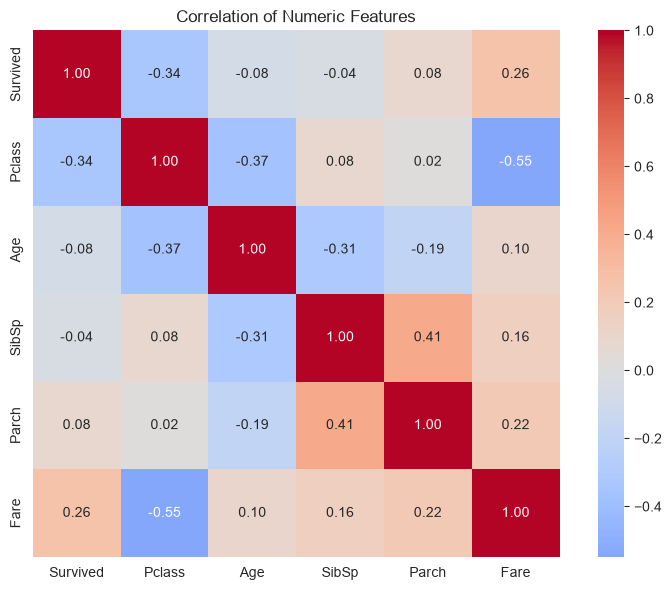

In [98]:
numeric_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
corr = train_eda[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)
plt.title('Correlation of Numeric Features')
plt.tight_layout()
plt.show()

### Age & Fare binning
Grouping Age and Fare into bins makes it easier to compare survival across ranges and gives us ready-to-use categorical features for modeling.
- `AgeGroup`: fixed life-stage bins (Child, Teen, Young Adult, Adult, Senior).
- `FareGroup`: quartile bins (Low, Medium, High, Very High).

             count  SurvivalRate
AgeGroup                        
Child           69         0.580
Teen            70         0.429
Young Adult    358         0.383
Adult          195         0.400
Senior          22         0.227


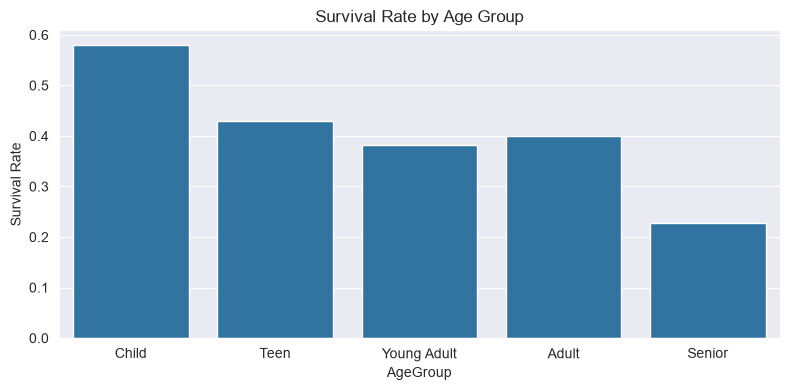

In [99]:
train_eda['AgeGroup'] = pd.cut(
    train_eda['Age'],
    bins=[0, 12, 18, 35, 60, 80],
    labels=['Child', 'Teen', 'Young Adult', 'Adult', 'Senior']
)

age_survival = (
    train_eda.groupby('AgeGroup', observed=True)['Survived']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'SurvivalRate'})
    .round(3)
)
print(age_survival)

plt.figure(figsize=(8, 4))
sns.barplot(data=train_eda, x='AgeGroup', y='Survived', errorbar=None)
plt.title('Survival Rate by Age Group')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

           count  SurvivalRate
FareGroup                     
Low          223         0.197
Medium       224         0.304
High         222         0.455
Very High    222         0.581


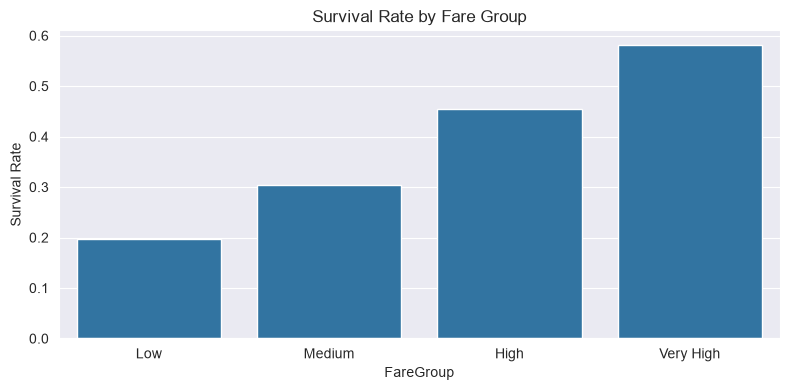

In [100]:
train_eda['FareGroup'] = pd.qcut(
    train_eda['Fare'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

fare_survival = (
    train_eda.groupby('FareGroup', observed=True)['Survived']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'SurvivalRate'})
    .round(3)
)
print(fare_survival)

plt.figure(figsize=(8, 4))
sns.barplot(data=train_eda, x='FareGroup', y='Survived', errorbar=None)
plt.title('Survival Rate by Fare Group')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

### IsAlone feature
Building on FamilySize, a simpler binary indicator for whether a passenger traveled alone captures the most striking survival gap: solo travelers fared noticeably worse than those traveling with family.

         count  SurvivalRate
IsAlone                     
0          354         0.506
1          537         0.304


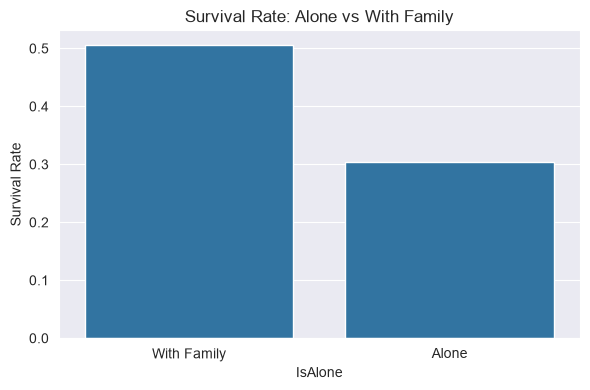

In [101]:
train_eda['IsAlone'] = (train_eda['FamilySize'] == 1).astype(int)

isalone_survival = (
    train_eda.groupby('IsAlone')['Survived']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'SurvivalRate'})
    .round(3)
)
print(isalone_survival)

plt.figure(figsize=(6, 4))
sns.barplot(data=train_eda, x='IsAlone', y='Survived', errorbar=None)
plt.xticks([0, 1], ['With Family', 'Alone'])
plt.title('Survival Rate: Alone vs With Family')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

### Cabin / Deck analysis
Although Cabin has ~77% missing values, its first letter identifies the deck. Passengers with a recorded cabin tend to be in higher classes, so deck may encode useful information despite the sparsity. Missing cabins are grouped into an "Unknown" category.

         count  SurvivalRate
Deck                        
Unknown    687         0.300
C           59         0.593
B           47         0.745
D           33         0.758
E           32         0.750
A           15         0.467
F           13         0.615
G            4         0.500
T            1         0.000


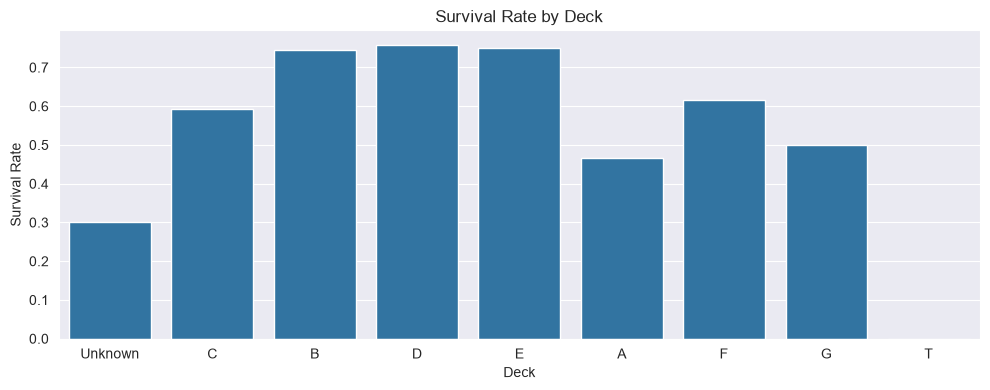

In [102]:
train_eda['Deck'] = train_eda['Cabin'].str[0].fillna('Unknown')

deck_survival = (
    train_eda.groupby('Deck')['Survived']
    .agg(['count', 'mean'])
    .rename(columns={'mean': 'SurvivalRate'})
    .sort_values('count', ascending=False)
    .round(3)
)
print(deck_survival)

plt.figure(figsize=(10, 4))
sns.barplot(
    data=train_eda,
    x='Deck',
    y='Survived',
    order=deck_survival.index,
    errorbar=None
)
plt.title('Survival Rate by Deck')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.show()

### Pclass × Sex interaction
Sex and Pclass are the two strongest individual predictors. The pivot table and heatmap below show how survival rates vary across their combinations.

Pclass      1      2      3
Sex                        
female  0.968  0.921  0.500
male    0.369  0.157  0.135


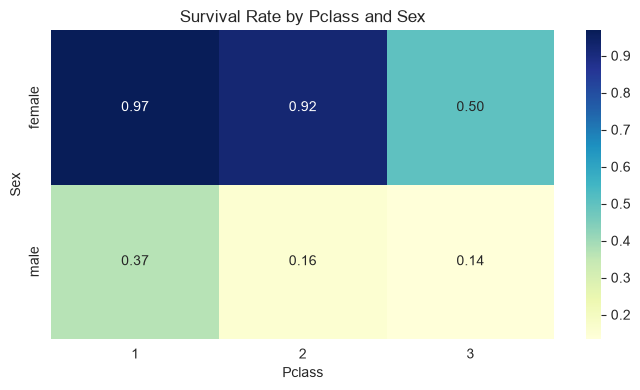

In [103]:
pclass_sex = train_eda.pivot_table(
    values='Survived',
    index='Sex',
    columns='Pclass',
    aggfunc='mean'
).round(3)

print(pclass_sex)

plt.figure(figsize=(7, 4))
sns.heatmap(pclass_sex, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Survival Rate by Pclass and Sex')
plt.tight_layout()
plt.show()

## Test overview

In [104]:
test.shape

(418, 11)

In [105]:
# Test data overview
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [106]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


In [107]:
display(test.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,418.0,NaN,NaN,NaN,1100.5,120.810458,892.0,996.25,1100.5,1204.75,1309.0
Pclass,418.0,NaN,NaN,NaN,2.26555,0.841838,1.0,1.0,3.0,3.0,3.0
Name,418,418,"Kelly, Mr. James",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,418,2,male,266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,332.0,NaN,NaN,NaN,30.27259,14.181209,0.17,21.0,27.0,39.0,76.0
SibSp,418.0,NaN,NaN,NaN,0.447368,0.89676,0.0,0.0,0.0,1.0,8.0
Parch,418.0,NaN,NaN,NaN,0.392344,0.981429,0.0,0.0,0.0,0.0,9.0
Ticket,418,363,PC 17608,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,417.0,NaN,NaN,NaN,35.627188,55.907576,0.0,7.8958,14.4542,31.5,512.3292
Cabin,91,76,B57 B59 B63 B66,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [108]:
# missing values overview
missing = pd.DataFrame({
    "missing_count": test.isna().sum(),
    "missing_pct": test.isna().mean() * 100
}).sort_values("missing_pct", ascending=False)

display(missing)

,missing_count,missing_pct
Cabin,327,78.229665
Age,86,20.574163
Fare,1,0.239234
PassengerId,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000


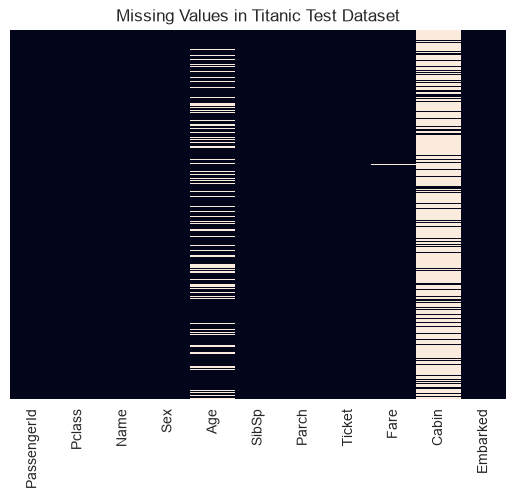

In [109]:
sns.heatmap(test.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in Titanic Test Dataset")
plt.show()

### Train vs test distribution comparison
To justify training on this split, we check that key feature distributions in `train` and `test` are reasonably similar. Large shifts between the two would signal distribution drift and hurt generalization.

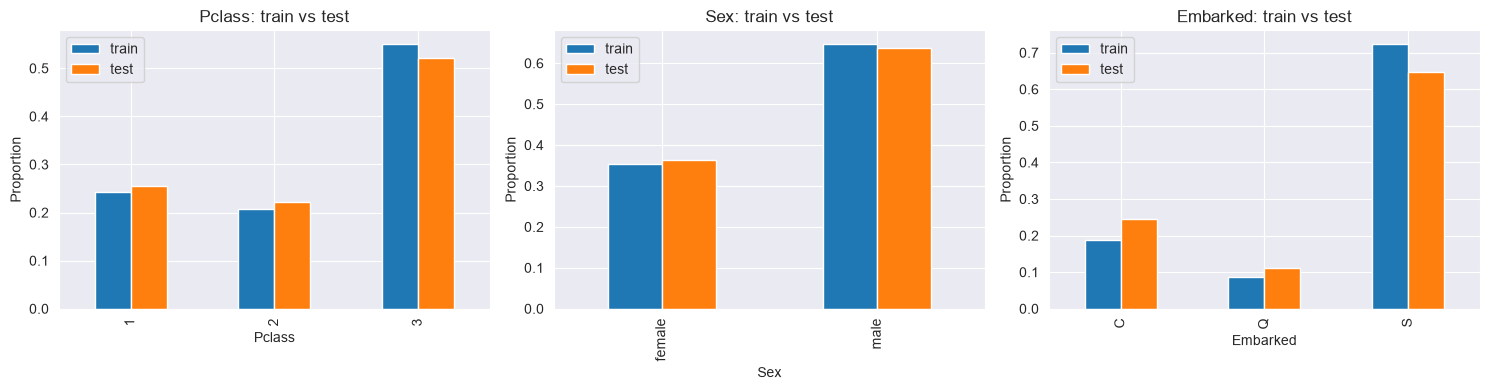

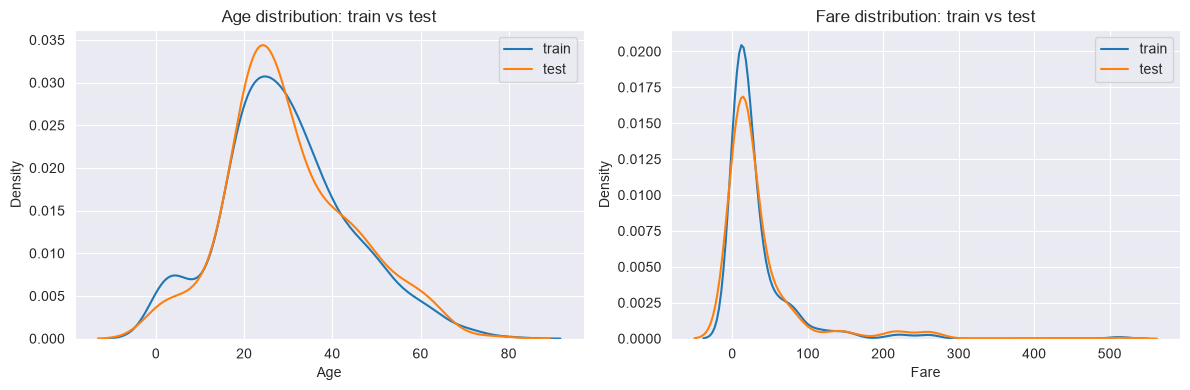

In [110]:
compare_cols = ['Pclass', 'Sex', 'Embarked']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, compare_cols):
    df_cmp = pd.DataFrame({
        'train': train[col].value_counts(normalize=True),
        'test':  test[col].value_counts(normalize=True),
    }).sort_index()
    df_cmp.plot(kind='bar', ax=ax)
    ax.set_title(f'{col}: train vs test')
    ax.set_ylabel('Proportion')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(train['Age'].dropna(), ax=axes[0], label='train')
sns.kdeplot(test['Age'].dropna(),  ax=axes[0], label='test')
axes[0].set_title('Age distribution: train vs test')
axes[0].legend()

sns.kdeplot(train['Fare'].dropna(), ax=axes[1], label='train')
sns.kdeplot(test['Fare'].dropna(),  ax=axes[1], label='test')
axes[1].set_title('Fare distribution: train vs test')
axes[1].legend()
plt.tight_layout()
plt.show()

## EDA summary & key findings

### Target
- **Survived** is imbalanced: 61.6% did not survive, 38.4% did.

### Strongest predictors
- **Sex**: females survived at 74.2% vs. males at 18.9%.
- **Pclass**: 1st class 63.0%, 2nd 47.3%, 3rd 24.2%.
- **Pclass × Sex interaction**: 1st-class females had near-certain survival (~97%) while 3rd-class males had the lowest (~14%).
- **Title**: Mr (15.7%) vs. Master (57.5%) shows that title captures age/role information beyond raw Sex.
- **Fare**: survivors paid a higher median fare (26.0 vs. 10.5); FareGroup tiers show a clear monotonic trend.
- **FamilySize / IsAlone**: solo travelers survived at ~30% vs. 50%+ for families of 2–4; very large families fared worst.
- **Age**: children show elevated survival; the overall mean difference between survivors and non-survivors is modest.
- **Deck**: passengers with a known cabin (upper decks) survived more often than those with unknown cabins, though cabin is mostly missing.

### Missing values
- **Cabin**: ~77% missing — use the Deck letter as a sparse categorical with an "Unknown" category.
- **Age**: ~20% missing — impute (median overall, or by Title/Pclass group).
- **Embarked**: 2 missing in train — impute with mode (`S`).
- **Fare**: 1 missing in test — impute with median.

### Preprocessing implications
- Encode categoricals: `Sex`, `Embarked`, `Title_Grouped`, `Deck`.
- Scale or bin `Fare` (heavy right skew, outliers up to 512).
- Candidate engineered features: `FamilySize`, `IsAlone`, `Title_Grouped`, `AgeGroup`, `FareGroup`, `Deck`.
- Train and test have similar Pclass/Sex/Embarked proportions and Age/Fare shapes, so a model trained on `train.csv` should generalize to `test.csv`.

These are associations observed in the sample and do not imply causation.